# Klasifikasi Tingkat Kematangan Pisang (Unripe, Ripe, Overripe) dengan CNN
**Proyek UTS Deep Learning (Tugas 1)** | Kelompok: `Kelompok 5` | Kelas: `Kelas IF B Pagi`

Anggota:
1) 231112553 - Reno Kurniawan Panjaitan
2) 231112268 - Gabriel Nicholas Dunant Saragih
3) 231112637 - Andi Aziz Prasetyo
4) 231112600 - Erico Adelorenzo Samosir
5) 231111885 - Dedi Sanjaya Nainggolan

---
### Alur notebook
| Bagian | Isi | CPMK |
|---|---|---|
| 1 | Memuat dataset, pembersihan (file rusak & duplikat) | - |
| 2 | EDA: distribusi kelas, contoh gambar | - |
| 3 | Split stratified 70/15/15 | - |
| 4 | Input pipeline `tf.data` + demo operasi tensor | 1 |
| 5 | Model: Baseline MLP dan CNN dasar | 2, 4 |
| 6 | Optimasi & regularisasi (Adam vs RMSProp, Dropout, BatchNorm, LR scheduling, EarlyStopping, monitoring) | 3 |
| 7 | Eksperimen perbaikan (data augmentation) | 3 |
| 8 | Evaluasi: accuracy, precision, recall, F1, confusion matrix, analisis kesalahan | - |
| 9 | Simpan model & inferensi gambar baru | - |

## 0. Setup & Konfigurasi

In [1]:
!unzip -q dataset.zip -d dataset

import os, json, random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_DIR = "dataset"
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 20
LR = 1e-3
EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")


CLASS_MAP = {}
KEEP_CLASSES = None
USE_CLASS_WEIGHT = False

for d in ("models", "logs", "outputs"):
    os.makedirs(d, exist_ok=True)
print("TensorFlow :", tf.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
GPU        : []


## 1. Memuat Dataset & Pembersihan
Label diambil dari **nama folder** tempat gambar berada. Dataset Kaggle sering sudah berisi subfolder `train/test`; tidak masalah, semua gambar dikumpulkan lalu **dibagi ulang** sendiri secara stratified supaya proporsinya terkontrol.

Pembersihan yang dilakukan: (1) membuang file gambar rusak, (2) membuang **duplikat persis** (hash MD5). Duplikat harus dibuang agar gambar yang sama tidak muncul di data latih dan data uji (*data leakage*) yang membuat akurasi tampak terlalu bagus.

In [2]:
def scan_dataset(data_dir):
    rows = []
    for root, _, files in os.walk(data_dir):
        for f in files:
            if f.lower().endswith(EXTS):
                raw = os.path.basename(root).strip().lower()
                rows.append((os.path.join(root, f), CLASS_MAP.get(raw, raw)))
    return pd.DataFrame(rows, columns=["path", "label"])

def is_valid(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df = scan_dataset(DATA_DIR)
assert len(df) > 0, f"Tidak ada gambar di '{DATA_DIR}'. Periksa struktur folder dataset."
if KEEP_CLASSES:
    df = df[df.label.isin(KEEP_CLASSES)]
n_raw = len(df)

df = df[df.path.map(is_valid)].copy()
n_valid = len(df)
df["hash"] = df.path.map(md5)
df = df.drop_duplicates("hash").reset_index(drop=True)

print(f"Gambar mentah : {n_raw}")
print(f"File rusak    : {n_raw - n_valid}")
print(f"Duplikat      : {n_valid - len(df)}")
print(f"Gambar dipakai: {len(df)}")

class_names = sorted(df.label.unique().tolist())
label2id = {c: i for i, c in enumerate(class_names)}
df["label_id"] = df.label.map(label2id)
NUM_CLASSES = len(class_names)
print("Kelas         :", class_names)
if NUM_CLASSES != 3:
    print("PERHATIAN: jumlah kelas =", NUM_CLASSES, "(rancangan awal 3 kelas). Atur CLASS_MAP / KEEP_CLASSES bila perlu.")

Gambar mentah : 735
File rusak    : 0
Duplikat      : 0
Gambar dipakai: 735
Kelas         : ['overripe', 'ripe', 'unripe']


## 2. Exploratory Data Analysis (EDA)

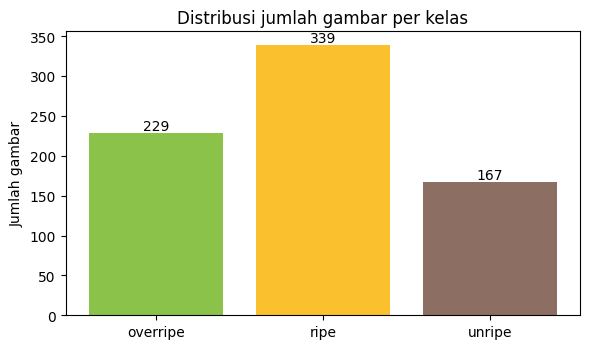

Rasio kelas terbesar / terkecil: 2.03 (jika > 1.5 pertimbangkan USE_CLASS_WEIGHT=True)


In [3]:
counts = df.label.value_counts().reindex(class_names)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(counts.index, counts.values, color=["#8bc34a", "#fbc02d", "#8d6e63", "#9e9e9e"][:NUM_CLASSES])
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_title("Distribusi jumlah gambar per kelas"); ax.set_ylabel("Jumlah gambar")
plt.tight_layout(); plt.savefig("outputs/distribusi_kelas.png", dpi=150); plt.show()
print("Rasio kelas terbesar / terkecil:", round(counts.max() / counts.min(), 2),
      "(jika > 1.5 pertimbangkan USE_CLASS_WEIGHT=True)")

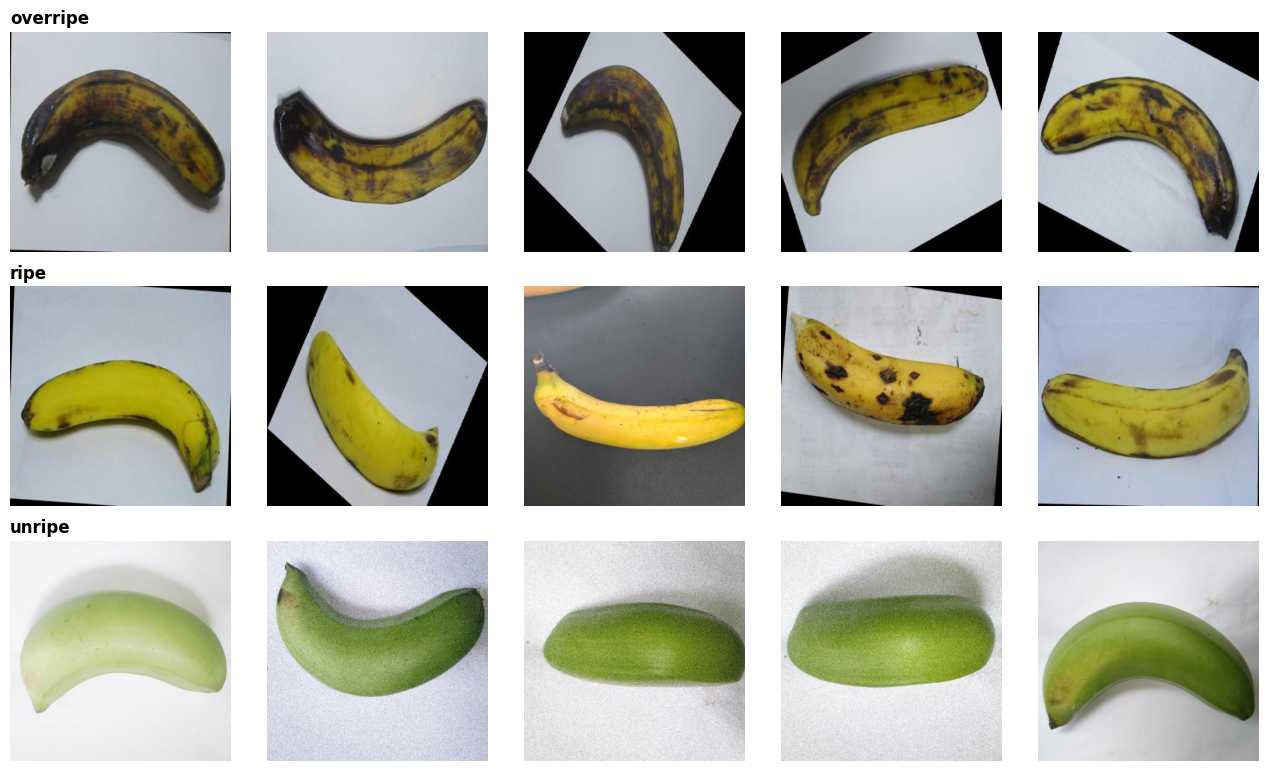

Ukuran asli gambar (lebar, tinggi) yang paling sering: {(416, 416): 200}


In [4]:
# Contoh gambar tiap kelas
N_SHOW = 5
fig, axes = plt.subplots(NUM_CLASSES, N_SHOW, figsize=(2.6 * N_SHOW, 2.6 * NUM_CLASSES), squeeze=False)
for r, c in enumerate(class_names):
    sub = df[df.label == c].sample(min(N_SHOW, (df.label == c).sum()), random_state=SEED)
    for k in range(N_SHOW):
        ax = axes[r, k]; ax.axis("off")
        if k < len(sub):
            ax.imshow(Image.open(sub.path.iloc[k]).convert("RGB"))
            if k == 0:
                ax.set_title(c, loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("outputs/contoh_gambar.png", dpi=150); plt.show()

sizes = [Image.open(p).size for p in df.sample(min(200, len(df)), random_state=SEED).path]
print("Ukuran asli gambar (lebar, tinggi) yang paling sering:", pd.Series(sizes).value_counts().head(5).to_dict())

## 3. Pembagian Data (Train / Validation / Test = 70 / 15 / 15)
Split dilakukan **stratified** agar proporsi kelas sama di ketiga subset. Data uji tidak dipakai sama sekali saat training maupun pemilihan model.

In [5]:
train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df.label_id, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.label_id, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

split_summary = pd.DataFrame({
    "train": train_df.label.value_counts(),
    "val": val_df.label.value_counts(),
    "test": test_df.label.value_counts(),
}).reindex(class_names)
split_summary.loc["TOTAL"] = split_summary.sum()
print(split_summary)

class_weight = None
if USE_CLASS_WEIGHT:
    w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df.label_id.values)
    class_weight = {i: float(x) for i, x in enumerate(w)}
    print("Class weight:", class_weight)

          train  val  test
label                     
overripe    160   34    35
ripe        237   51    51
unripe      117   25    25
TOTAL       514  110   111


## 4. Input Pipeline `tf.data` (CPMK 1)
Setiap gambar dibaca dari disk, di-decode menjadi **tensor** `(height, width, 3)`, di-resize ke 128x128, dan dinormalisasi ke rentang 0-1. Data latih di-*shuffle*, lalu semua subset di-*batch* dan di-*prefetch* agar GPU/CPU tidak menunggu proses I/O.

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0          # normalisasi piksel 0-1
    return img, label

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.label_id.values.astype("int32")))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)          # tidak di-shuffle agar urutan = test_df
print(train_ds.element_spec)

(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


### Demo operasi tensor, Perceptron, dan gradient descent (CPMK 1 & 2)
Sel ini memperlihatkan representasi citra sebagai tensor, operasi dasar tensor, perhitungan satu lapisan Dense secara manual, dan satu langkah *gradient descent* dengan `GradientTape` (konsep di balik backpropagation).

In [7]:
x_batch, y_batch = next(iter(train_ds))
print("Shape batch gambar   :", x_batch.shape, "-> (batch, height, width, channel)")
print("Dtype                :", x_batch.dtype)
print("Rank / jumlah elemen :", int(tf.rank(x_batch)), "/", int(tf.size(x_batch)))
print("Min / Max piksel     :", float(tf.reduce_min(x_batch)), "/", float(tf.reduce_max(x_batch)))
print("Label 8 gambar awal  :", [class_names[i] for i in y_batch.numpy()[:8]])
print("Rata-rata kanal R,G,B:", np.round(tf.reduce_mean(x_batch, axis=[0, 1, 2]).numpy(), 3))

# Operasi reshape (Flatten) -> input untuk MLP
flat = tf.reshape(x_batch, (tf.shape(x_batch)[0], -1))
print("Shape setelah flatten:", flat.shape)

# Satu lapisan Dense manual dengan 4 neuron: y = ReLU(XW + b)
W = tf.random.normal((flat.shape[1], 4), stddev=0.01, seed=SEED)
b = tf.zeros((4,))
out = tf.nn.relu(tf.matmul(flat, W) + b)
print("Output Dense manual  :", out.shape)

# Satu langkah gradient descent: minimalkan loss = (3w - 12)^2, solusi ideal w = 4
w = tf.Variable(2.0)
with tf.GradientTape() as tape:
    loss = (3.0 * w - 12.0) ** 2
grad = tape.gradient(loss, w)
w_before = float(w.numpy())
w.assign_sub(0.01 * grad)
print(f"Gradient descent     : w {w_before:.3f} -> {float(w.numpy()):.3f} (gradien={float(grad):.2f}, lr=0.01)")

Shape batch gambar   : (32, 128, 128, 3) -> (batch, height, width, channel)
Dtype                : <dtype: 'float32'>
Rank / jumlah elemen : 4 / 1572864
Min / Max piksel     : 0.0 / 1.0
Label 8 gambar awal  : ['unripe', 'overripe', 'ripe', 'overripe', 'overripe', 'ripe', 'ripe', 'overripe']
Rata-rata kanal R,G,B: [0.599 0.61  0.552]
Shape setelah flatten: (32, 49152)
Output Dense manual  : (32, 4)
Gradient descent     : w 2.000 -> 2.360 (gradien=-36.00, lr=0.01)


## 5. Arsitektur Model (CPMK 2 & 4)

**Baseline MLP** (CPMK 2): `Flatten -> Dense(256, ReLU) -> Dropout -> Dense(128, ReLU) -> Dense(softmax)`. MLP memperlakukan piksel sebagai vektor datar sehingga kehilangan informasi spasial; model ini dipakai sebagai pembanding.

**CNN dasar** (CPMK 4): 3 blok `Conv2D -> BatchNorm -> ReLU -> MaxPool` (32, 64, 128 filter), lalu `Flatten -> Dense(64) -> Dropout(0.3) -> Dense(softmax)`. Parameter `augment=True` menambahkan lapisan data augmentation yang **hanya aktif saat training** (dipakai pada eksperimen perbaikan).

In [8]:
def build_mlp(name="mlp_baseline"):
    return keras.Sequential([
        layers.Input((IMG_SIZE, IMG_SIZE, 3)),
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name=name)

def build_cnn(name="cnn", augment=False, dropout=0.3):
    blocks = [layers.Input((IMG_SIZE, IMG_SIZE, 3))]
    if augment:
        blocks.append(keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.08),
            layers.RandomZoom(0.10),
            layers.RandomBrightness(0.15, value_range=(0, 1)),
        ], name="augmentation"))
    for filters in (32, 64, 128):
        blocks += [
            layers.Conv2D(filters, 3, padding="same", use_bias=False),
            layers.BatchNormalization(),
            layers.ReLU(),
            layers.MaxPooling2D(),
        ]
    blocks += [
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ]
    return keras.Sequential(blocks, name=name)

build_mlp().summary()
build_cnn().summary()

Model: "mlp_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    12,583,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,616,451 (48.13 MB)

 Trainable params: 12,616,451 (48.13 MB)

 Non-trainable params: 0 (0.00 B)

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │     2,097,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,191,331 (8.36 MB)

 Trainable params: 2,190,883 (8.36 MB)

 Non-trainable params: 448 (1.75 KB)

## 6. Optimasi, Regularisasi & Monitoring (CPMK 3)
| Komponen | Pengaturan |
|---|---|
| Loss function | `sparse_categorical_crossentropy` (label berupa integer) |
| Optimizer | Adam dan RMSProp (dibandingkan) |
| Regularisasi | Dropout 0.3, Batch Normalization |
| Learning rate scheduling | `ReduceLROnPlateau` (LR x0.5 jika `val_loss` tidak membaik 2 epoch) |
| Early stopping | pantau `val_loss`, patience 5, `restore_best_weights=True` |
| Model monitoring | kurva loss/accuracy, `ModelCheckpoint`, `CSVLogger`, `TensorBoard` |

In [9]:
def make_optimizer(name, lr=LR):
    return {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop}[name](learning_rate=lr)

def get_callbacks(name):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
        keras.callbacks.ModelCheckpoint(f"models/{name}.keras", monitor="val_loss", save_best_only=True),
        keras.callbacks.TensorBoard(log_dir=f"logs/{name}"),
        keras.callbacks.CSVLogger(f"logs/{name}.csv"),
    ]

histories, trained = {}, {}

def run_experiment(name, model, optimizer_name="adam", epochs=EPOCHS):
    model.compile(optimizer=make_optimizer(optimizer_name),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                  callbacks=get_callbacks(name), class_weight=class_weight, verbose=2)
    histories[name] = h.history
    trained[name] = model
    return h

def plot_history(name):
    h = histories[name]
    ep = range(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(ep, h["loss"], label="train"); ax[0].plot(ep, h["val_loss"], label="validation")
    ax[0].set_title(f"Loss - {name}"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, h["accuracy"], label="train"); ax[1].plot(ep, h["val_accuracy"], label="validation")
    ax[1].set_title(f"Accuracy - {name}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"outputs/kurva_{name}.png", dpi=150); plt.show()

### Eksperimen 1: Baseline MLP + Adam

Epoch 1/20
17/17 - 5s - 291ms/step - accuracy: 0.3424 - loss: 21.6279 - val_accuracy: 0.4636 - val_loss: 5.8034 - learning_rate: 0.0010
Epoch 2/20
17/17 - 3s - 180ms/step - accuracy: 0.4105 - loss: 8.6299 - val_accuracy: 0.6273 - val_loss: 1.6075 - learning_rate: 0.0010
Epoch 3/20
17/17 - 5s - 272ms/step - accuracy: 0.4163 - loss: 4.3166 - val_accuracy: 0.3182 - val_loss: 2.2083 - learning_rate: 0.0010
Epoch 4/20
17/17 - 4s - 215ms/step - accuracy: 0.4436 - loss: 2.4534 - val_accuracy: 0.3545 - val_loss: 1.1646 - learning_rate: 0.0010
Epoch 5/20
17/17 - 3s - 183ms/step - accuracy: 0.4942 - loss: 1.2940 - val_accuracy: 0.6182 - val_loss: 0.8553 - learning_rate: 0.0010
Epoch 6/20
17/17 - 5s - 289ms/step - accuracy: 0.5642 - loss: 1.0756 - val_accuracy: 0.7091 - val_loss: 0.6641 - learning_rate: 0.0010
Epoch 7/20
17/17 - 4s - 224ms/step - accuracy: 0.5953 - loss: 0.8456 - val_accuracy: 0.7364 - val_loss: 0.6248 - learning_rate: 0.0010
Epoch 8/20
17/17 - 3s - 161ms/step - accuracy: 0.6381 

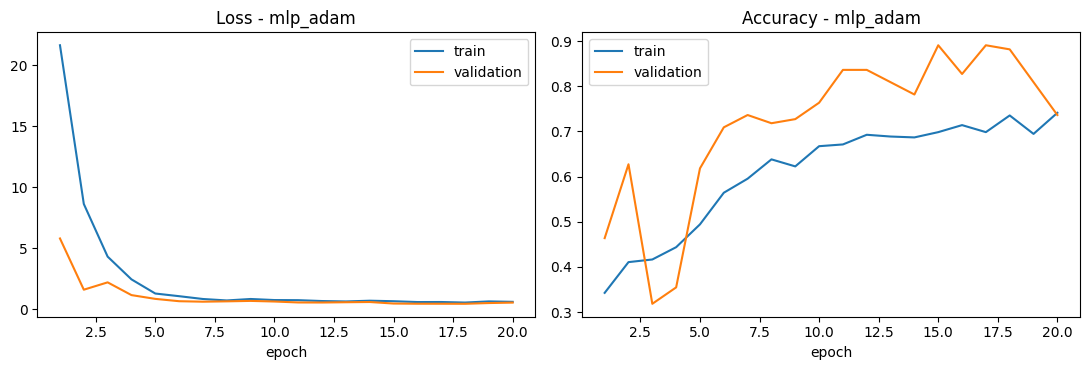

In [10]:
run_experiment("mlp_adam", build_mlp(), "adam")
plot_history("mlp_adam")

### Eksperimen 2: CNN dasar + Adam

Epoch 1/20
17/17 - 27s - 2s/step - accuracy: 0.6984 - loss: 2.8126 - val_accuracy: 0.3091 - val_loss: 1.4765 - learning_rate: 0.0010
Epoch 2/20
17/17 - 38s - 2s/step - accuracy: 0.9027 - loss: 0.2425 - val_accuracy: 0.4909 - val_loss: 1.0677 - learning_rate: 0.0010
Epoch 3/20
17/17 - 40s - 2s/step - accuracy: 0.9241 - loss: 0.1889 - val_accuracy: 0.7182 - val_loss: 0.8207 - learning_rate: 0.0010
Epoch 4/20
17/17 - 22s - 1s/step - accuracy: 0.9319 - loss: 0.1444 - val_accuracy: 0.6545 - val_loss: 0.7291 - learning_rate: 0.0010
Epoch 5/20
17/17 - 18s - 1s/step - accuracy: 0.9222 - loss: 0.1960 - val_accuracy: 0.6273 - val_loss: 0.8236 - learning_rate: 0.0010
Epoch 6/20
17/17 - 33s - 2s/step - accuracy: 0.9475 - loss: 0.1269 - val_accuracy: 0.6818 - val_loss: 0.6745 - learning_rate: 0.0010
Epoch 7/20
17/17 - 24s - 1s/step - accuracy: 0.9436 - loss: 0.1334 - val_accuracy: 0.4636 - val_loss: 2.6404 - learning_rate: 0.0010
Epoch 8/20

Epoch 8: ReduceLROnPlateau reducing learning rate to 0.00

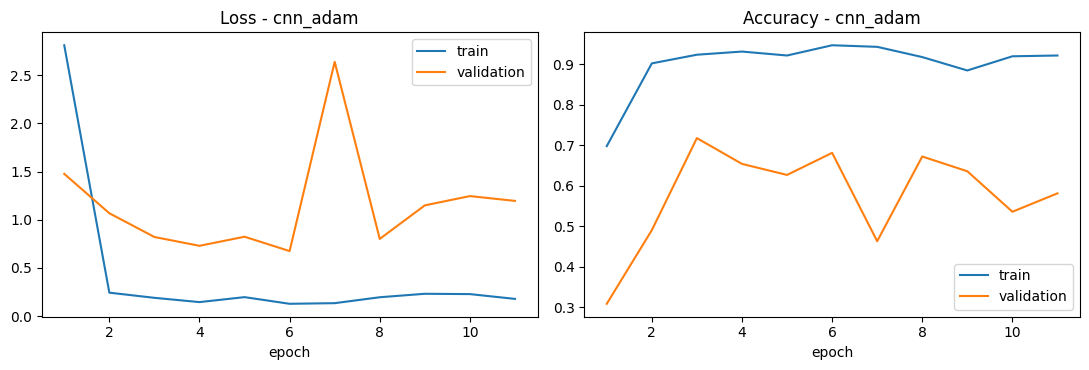

In [11]:
run_experiment("cnn_adam", build_cnn(), "adam")
plot_history("cnn_adam")

### Eksperimen 3: CNN dasar + RMSProp (perbandingan optimizer)

Epoch 1/20
17/17 - 19s - 1s/step - accuracy: 0.6712 - loss: 11.0725 - val_accuracy: 0.4545 - val_loss: 1.0112 - learning_rate: 0.0010
Epoch 2/20
17/17 - 20s - 1s/step - accuracy: 0.8463 - loss: 1.0129 - val_accuracy: 0.6091 - val_loss: 0.8654 - learning_rate: 0.0010
Epoch 3/20
17/17 - 19s - 1s/step - accuracy: 0.9144 - loss: 0.2752 - val_accuracy: 0.6545 - val_loss: 0.7446 - learning_rate: 0.0010
Epoch 4/20
17/17 - 20s - 1s/step - accuracy: 0.8677 - loss: 0.4302 - val_accuracy: 0.4727 - val_loss: 0.9365 - learning_rate: 0.0010
Epoch 5/20

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
17/17 - 19s - 1s/step - accuracy: 0.9397 - loss: 0.1885 - val_accuracy: 0.4909 - val_loss: 2.0067 - learning_rate: 0.0010
Epoch 6/20
17/17 - 20s - 1s/step - accuracy: 0.9144 - loss: 0.2844 - val_accuracy: 0.7545 - val_loss: 0.5734 - learning_rate: 5.0000e-04
Epoch 7/20
17/17 - 18s - 1s/step - accuracy: 0.9280 - loss: 0.1643 - val_accuracy: 0.6091 - val_loss: 0.6939 - learning_

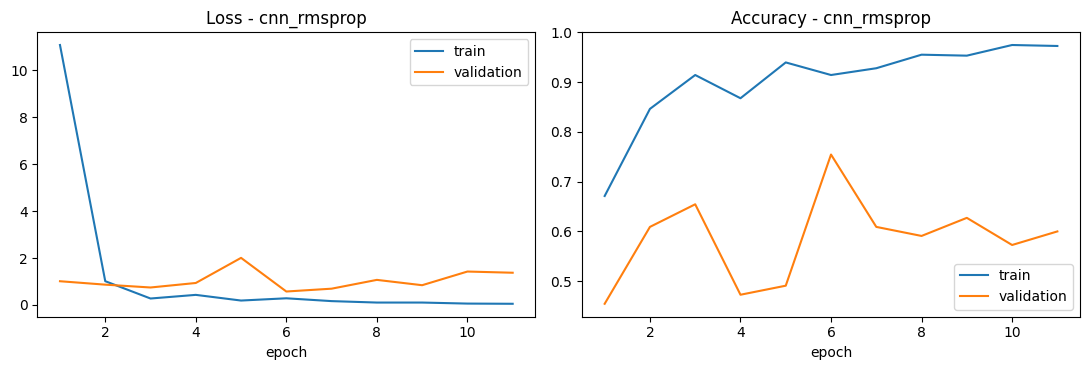

In [12]:
run_experiment("cnn_rmsprop", build_cnn(name="cnn_rmsprop"), "rmsprop")
plot_history("cnn_rmsprop")

## 7. Eksperimen Perbaikan Model: Data Augmentation
Jika pada Eksperimen 2/3 terlihat **overfitting** (akurasi train jauh di atas validation, atau `val_loss` naik), data augmentation (flip, rotasi, zoom, brightness) membantu model melihat variasi data yang lebih banyak. Augmentation hanya aktif saat training; data validasi dan uji tidak diubah.

Epoch 1/20
17/17 - 22s - 1s/step - accuracy: 0.6809 - loss: 3.4141 - val_accuracy: 0.3091 - val_loss: 1.5984 - learning_rate: 0.0010
Epoch 2/20
17/17 - 20s - 1s/step - accuracy: 0.8891 - loss: 0.3802 - val_accuracy: 0.2455 - val_loss: 1.2213 - learning_rate: 0.0010
Epoch 3/20
17/17 - 20s - 1s/step - accuracy: 0.9027 - loss: 0.2817 - val_accuracy: 0.2273 - val_loss: 1.9852 - learning_rate: 0.0010
Epoch 4/20

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
17/17 - 20s - 1s/step - accuracy: 0.9183 - loss: 0.2262 - val_accuracy: 0.2545 - val_loss: 1.8133 - learning_rate: 0.0010
Epoch 5/20
17/17 - 20s - 1s/step - accuracy: 0.9416 - loss: 0.1592 - val_accuracy: 0.2273 - val_loss: 2.4902 - learning_rate: 5.0000e-04
Epoch 6/20

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
17/17 - 20s - 1s/step - accuracy: 0.9261 - loss: 0.1836 - val_accuracy: 0.2273 - val_loss: 2.8232 - learning_rate: 5.0000e-04
Epoch 7/20
17/17 - 19s - 1s/step - accur

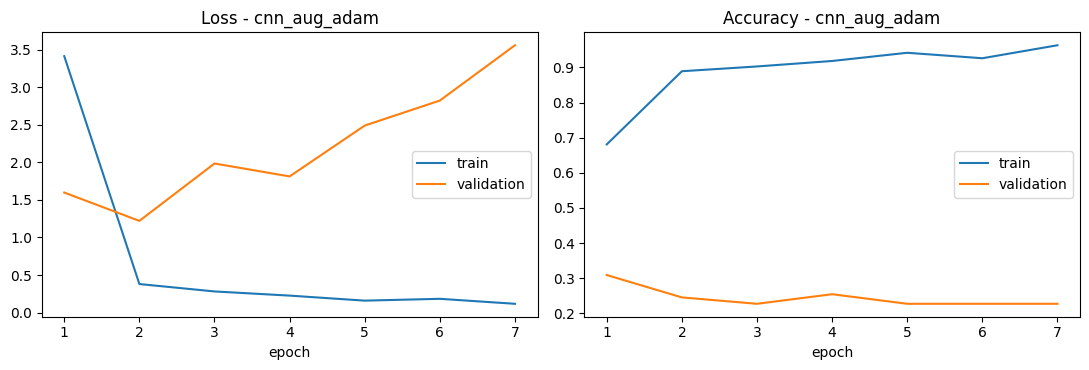

In [13]:
run_experiment("cnn_aug_adam", build_cnn(name="cnn_aug", augment=True), "adam")
plot_history("cnn_aug_adam")

## 8. Evaluasi & Perbandingan Model
Model terbaik dipilih berdasarkan **akurasi validasi** (bukan data uji). Data uji baru dipakai untuk melaporkan performa akhir.

In [14]:
y_true = test_df.label_id.values

def evaluate_model(name):
    m = trained[name]
    val_loss, val_acc = m.evaluate(val_ds, verbose=0)
    probs = m.predict(test_ds, verbose=0)
    y_pred = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {
        "model": name,
        "params": m.count_params(),
        "epoch_dijalankan": len(histories[name]["loss"]),
        "val_loss": round(val_loss, 4),
        "val_acc": round(val_acc, 4),
        "test_acc": round(float((y_pred == y_true).mean()), 4),
        "precision_macro": round(p, 4),
        "recall_macro": round(r, 4),
        "f1_macro": round(f1, 4),
    }

results = pd.DataFrame([evaluate_model(n) for n in trained]).set_index("model")
results.to_csv("outputs/perbandingan_model.csv")
print(results)

best_name = results.val_acc.idxmax()
best_model = trained[best_name]
print("\nModel terbaik (berdasar val_acc):", best_name)

                params  epoch_dijalankan  val_loss  val_acc  test_acc  \
model                                                                   
mlp_adam      12616451                20    0.4525   0.8818    0.8108   
cnn_adam       2191331                11    0.6745   0.6818    0.7387   
cnn_rmsprop    2191331                11    0.5734   0.7545    0.7027   
cnn_aug_adam   2191331                 7    1.2213   0.2455    0.2432   

              precision_macro  recall_macro  f1_macro  
model                                                  
mlp_adam               0.8057        0.7755    0.7854  
cnn_adam               0.7343        0.7213    0.7013  
cnn_rmsprop            0.7738        0.7126    0.6608  
cnn_aug_adam           0.1569        0.3295    0.2023  

Model terbaik (berdasar val_acc): mlp_adam


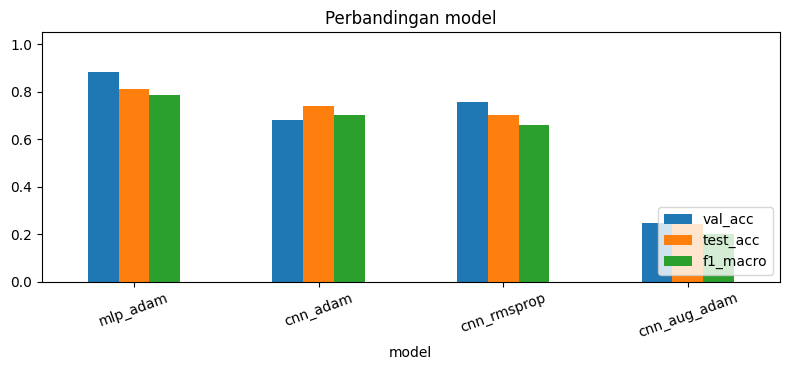

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8))
results[["val_acc", "test_acc", "f1_macro"]].plot.bar(ax=ax)
ax.set_ylim(0, 1.05); ax.set_title("Perbandingan model"); ax.legend(loc="lower right")
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig("outputs/perbandingan_model.png", dpi=150); plt.show()

### Laporan klasifikasi & confusion matrix (model terbaik, data uji)

              precision    recall  f1-score   support

    overripe     0.8276    0.6857    0.7500        35
        ripe     0.8167    0.9608    0.8829        51
      unripe     0.7727    0.6800    0.7234        25

    accuracy                         0.8108       111
   macro avg     0.8057    0.7755    0.7854       111
weighted avg     0.8102    0.8108    0.8051       111



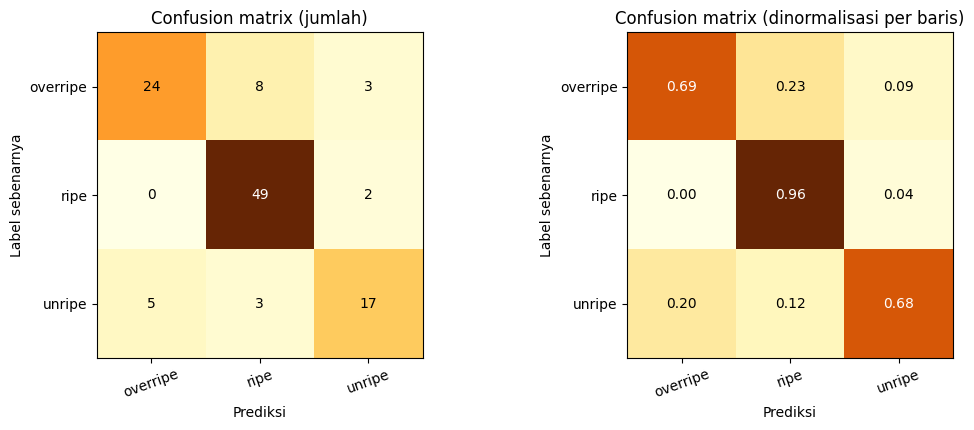

In [16]:
probs = best_model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, mat, title, fmt in ((axes[0], cm, "Confusion matrix (jumlah)", "d"),
                            (axes[1], cm_norm, "Confusion matrix (dinormalisasi per baris)", ".2f")):
    im = ax.imshow(mat, cmap="YlOrBr")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=20)
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label sebenarnya"); ax.set_title(title)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center",
                    color="white" if mat[i, j] > mat.max() / 2 else "black")
plt.tight_layout(); plt.savefig("outputs/confusion_matrix.png", dpi=150); plt.show()

### Analisis kesalahan

Kesalahan terbanyak (sebenarnya -> diprediksi : jumlah):
  overripe -> ripe : 8
  unripe -> overripe : 5
  overripe -> unripe : 3
  unripe -> ripe : 3
  ripe -> unripe : 2

Total salah prediksi: 21 dari 111


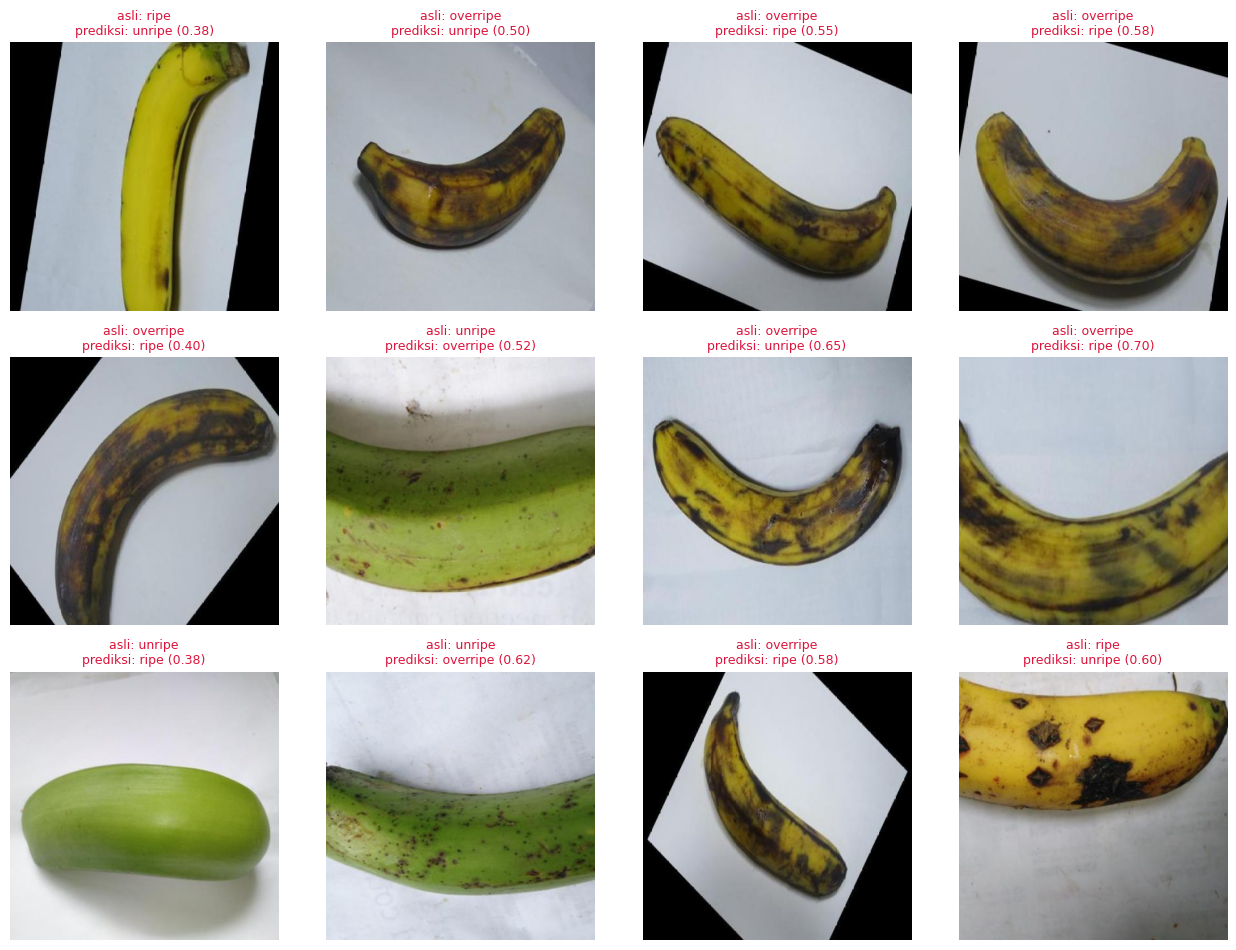

In [17]:
pairs = [(class_names[i], class_names[j], int(cm[i, j]))
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
print("Kesalahan terbanyak (sebenarnya -> diprediksi : jumlah):")
for a, b, n in pairs[:5]:
    print(f"  {a} -> {b} : {n}")

wrong = np.where(y_pred != y_true)[0]
print(f"\nTotal salah prediksi: {len(wrong)} dari {len(y_true)}")
show = wrong[:12]
if len(show):
    cols = 4; rows = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.2 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, idx in zip(axes.ravel(), show):
        ax.imshow(Image.open(test_df.path[idx]).convert("RGB"))
        ax.set_title(f"asli: {class_names[y_true[idx]]}\nprediksi: {class_names[y_pred[idx]]} ({probs[idx].max():.2f})",
                     fontsize=9, color="crimson")
    plt.tight_layout(); plt.savefig("outputs/contoh_salah_prediksi.png", dpi=150); plt.show()

**Catatan analisis (isi setelah training selesai):**
- Bandingkan MLP vs CNN: ...
- Bandingkan Adam vs RMSProp: ...
- Apakah augmentation mengurangi overfitting? ...
- Pasangan kelas yang paling sering tertukar dan kemungkinan penyebabnya (misalnya batas antara *ripe* dan *overripe* tidak tegas, pencahayaan, bayangan): ...

## 9. Simpan Model & Inferensi Gambar Baru (untuk Video Demo)

Tersimpan: models/best_model.keras dan models/class_names.json


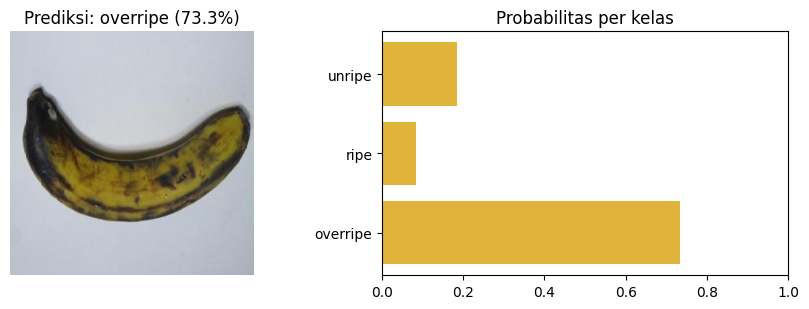

('overripe', {'overripe': 0.7327321171760559, 'ripe': 0.08319704979658127, 'unripe': 0.18407084047794342})


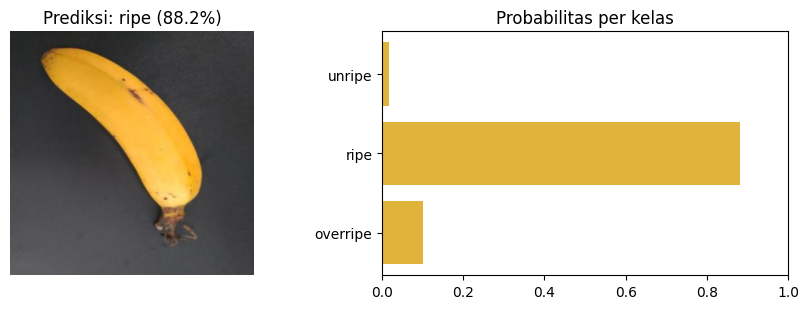

('ripe', {'overripe': 0.10143554210662842, 'ripe': 0.8815197348594666, 'unripe': 0.017044760286808014})


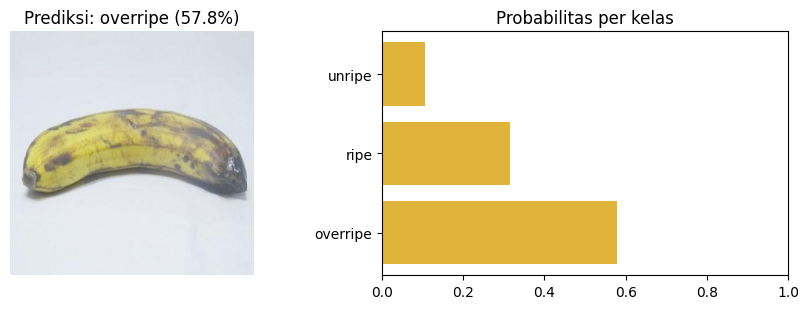

('overripe', {'overripe': 0.5782365798950195, 'ripe': 0.3156674802303314, 'unripe': 0.10609593242406845})


In [18]:
best_model.save("models/best_model.keras")
with open("models/class_names.json", "w") as f:
    json.dump({"class_names": class_names, "img_size": IMG_SIZE, "best_model": best_name}, f, indent=2)
print("Tersimpan: models/best_model.keras dan models/class_names.json")

def predict_image(path, model=best_model, show=True):
    # preprocessing identik dengan pipeline training
    img, _ = load_image(path, 0)
    probs = model.predict(img[None, ...], verbose=0)[0]
    k = int(probs.argmax())
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
        ax[0].imshow(Image.open(path).convert("RGB")); ax[0].axis("off")
        ax[0].set_title(f"Prediksi: {class_names[k]} ({probs[k]*100:.1f}%)")
        ax[1].barh(class_names, probs, color="#e0b43a"); ax[1].set_xlim(0, 1)
        ax[1].set_title("Probabilitas per kelas")
        plt.tight_layout(); plt.show()
    return class_names[k], {c: float(p) for c, p in zip(class_names, probs)}

# Demo: 3 gambar acak dari data uji (ganti dengan path foto pisang Anda sendiri)
for p in test_df.sample(min(3, len(test_df)), random_state=1).path:
    print(predict_image(p))

### Visualisasi TensorBoard (opsional, untuk bagian model monitoring)
Jalankan di sel baru: `%load_ext tensorboard` lalu `%tensorboard --logdir logs`

---
**Berkas hasil** ada di folder `outputs/` (grafik & tabel untuk laporan), `models/` (model terlatih), dan `logs/` (log training).

In [19]:
!zip -qr hasil_proyek.zip models outputs logs
from google.colab import files
files.download("hasil_proyek.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>